<a href="https://colab.research.google.com/github/deep25/DI-Bootcamp-Stage1/blob/main/Week2_challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
files.upload()

Saving US Superstore data.xls to US Superstore data.xls


{'US Superstore data.xls': b'\xd0\xcf\x11\xe0\xa1\xb1\x1a\xe1\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00>\x00\x03\x00\xfe\xff\t\x00\x06\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x004\x00\x00\x00\x01\x00\x00\x00\x00\x00\x00\x00\x00\x10\x00\x00s\x19\x00\x00\x01\x00\x00\x00\xfe\xff\xff\xff\x00\x00\x00\x00\x00\x00\x00\x00b\x00\x00\x00\xe3\x00\x00\x00d\x01\x00\x00\xe5\x01\x00\x00f\x02\x00\x00\xe7\x02\x00\x00h\x03\x00\x00\xe9\x03\x00\x00j\x04\x00\x00\xeb\x04\x00\x00l\x05\x00\x00\xed\x05\x00\x00n\x06\x00\x00\xef\x06\x00\x00p\x07\x00\x00\xf1\x07\x00\x00r\x08\x00\x00\xf3\x08\x00\x00t\t\x00\x00\xf5\t\x00\x00v\n\x00\x00\xf7\n\x00\x00x\x0b\x00\x00\xf9\x0b\x00\x00z\x0c\x00\x00\xfb\x0c\x00\x00|\r\x00\x00\xfd\r\x00\x00~\x0e\x00\x00\xff\x0e\x00\x00\x80\x0f\x00\x00\xe1\x0f\x00\x00b\x10\x00\x00\xe3\x10\x00\x00d\x11\x00\x00\xe5\x11\x00\x00f\x12\x00\x00\xe7\x12\x00\x00h\x13\x00\x00\xe9\x13\x00\x00j\x14\x00\x00\xeb\x14\x00\x00l\x15\x00\x00\xed\x15\x00\x00n\x16\x00\x00\xef\x16\x00\x00p\x1

In [2]:
!pip install xlrd
import pandas as pd

xls_path = '/content/US Superstore data.xls'

df = pd.read_excel(xls_path, engine='xlrd')

csv_path = '/content/US_Superstore_data.csv'
df.to_csv(csv_path, index=False)
print(f"Successfully converted and saved as: {csv_path}")

display(df.head())

Successfully converted and saved as: /content/US_Superstore_data.csv


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


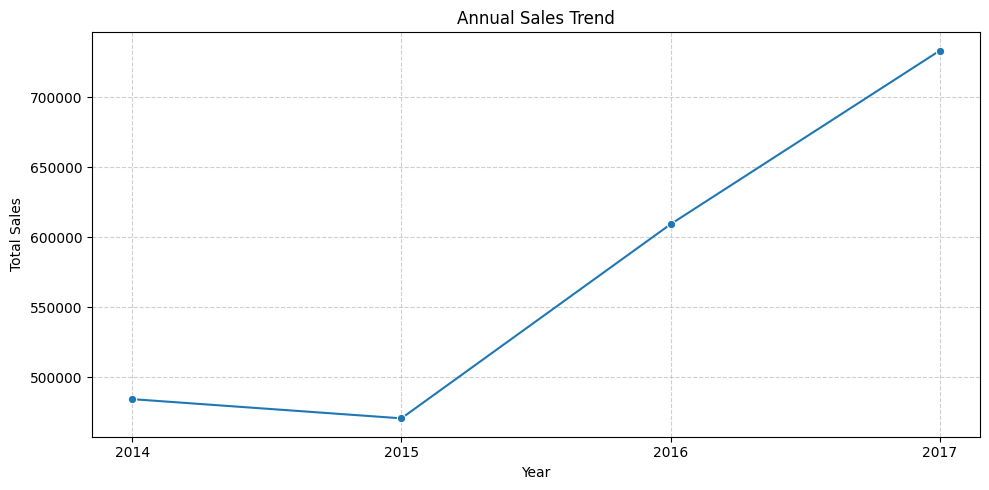

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df['Order Date'] = pd.to_datetime(df['Order Date'])

df['Year'] = df['Order Date'].dt.year

yearly_sales = df.groupby('Year')['Sales'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(x='Year', y='Sales', data=yearly_sales, marker='o')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.title('Annual Sales Trend')
plt.xticks(yearly_sales['Year'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [10]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
import seaborn as sns

sales_data = df.groupby('States')['Sales'].sum().reset_index()
sales_data = sales_data.sort_values(by='Sales', ascending=False)




In [14]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

regions = ['All'] + list(df['Region'].unique())
sort_options = ['Highest Sales first', 'Lowest Sales first', 'Alphabetical (A-Z)']

@interact(
    region=widgets.Dropdown(options=regions, description='Region:', value='All'),
    sort_by=widgets.Dropdown(options=sort_options, description='Sort States:', value='Highest Sales first'),
    top_n=widgets.IntSlider(min=5, max=50, step=1, value=15, description='Show Top N:')
)

def plot_interactive_sales(region, sort_by, top_n):
    if region == 'All':
        filtered_df = df
    else:
        filtered_df = df[df['Region'] == region]

    state_data = filtered_df.groupby('State')['Sales'].sum().reset_index()

    if sort_by == 'Highest Sales first':
        state_data = state_data.sort_values(by='Sales', ascending=False)
    elif sort_by == 'Lowest Sales first':
        state_data = state_data.sort_values(by='Sales', ascending=True)
    else:
        state_data = state_data.sort_values(by='State', ascending=True)

    state_data = state_data.head(top_n)

    plt.figure(figsize=(12, 6))
    sns.barplot(x='Sales', y='State', data=state_data, palette='viridis', hue='State', legend=False)

    plt.title(f'Sales Distribution by State (Region: {region})', fontsize=14, fontweight='bold')
    plt.xlabel('Total Sales ($)', fontsize=12)
    plt.ylabel('State', fontsize=12)
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='Region:', options=('All', 'South', 'West', 'Central', 'East'), val…

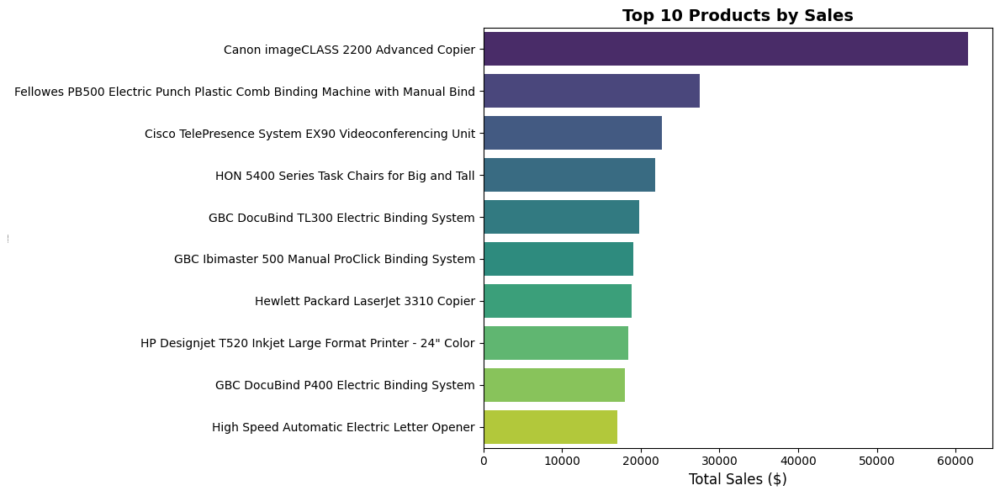

In [15]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

top10_products = df.groupby('Product Name')['Sales'].sum().reset_index()
top10_products = top10_products.sort_values(by='Sales', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x='Sales', y='Product Name', data=top10_products, palette='viridis', hue='Product Name', legend=False)

plt.title('Top 10 Products by Sales', fontsize=14, fontweight='bold')
plt.xlabel('Total Sales ($)', fontsize=12)
plt.ylabel('Product Name', fontsize=1)
plt.tight_layout()
plt.show()

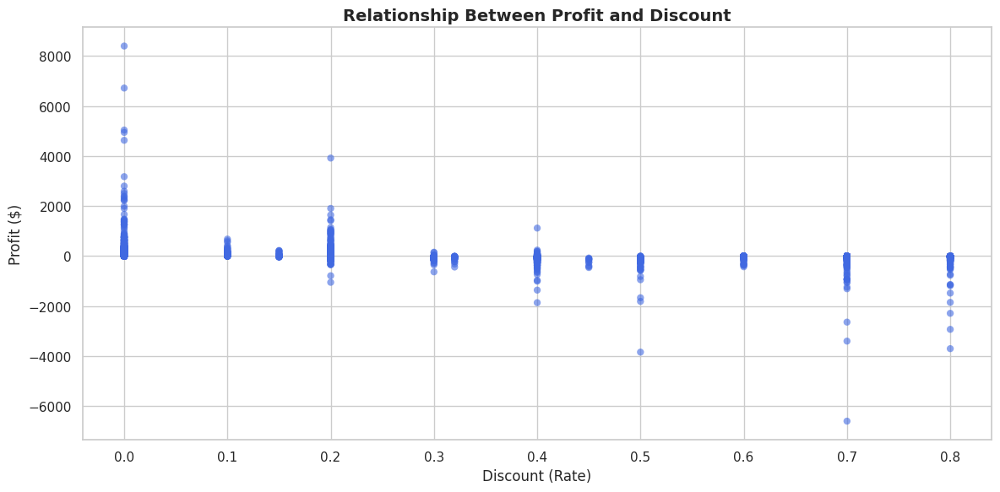

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))
sns.scatterplot(x='Discount', y='Profit', data=df, color='royalblue', alpha=0.6, edgecolor='none')
plt.title('Relationship Between Profit and Discount', fontsize=14, fontweight='bold')
plt.xlabel('Discount (Rate)', fontsize=12)
plt.ylabel('Profit ($)', fontsize=12)

plt.tight_layout()
plt.show()

Both matplolib and seaborn has it's own strenght. I like metplot for having many capabilities, options and values. On the other hand seaborn is very easy and with one line you can plot the graph. When combined together they work the best.

Sales Trend: Annual sales rose steadily over the years, peaking in 2017 at over $733,000.
Top States:California and New York lead the nation in sales.
Top Product:The Canon imageCLASS 2200 Advanced Copie is our highest revenue driver, bringing in over $$733,000.

Top States:California and New York lead the nation in sales.

Top Product: The Canon imageCLASS 2200 Advanced Copier  is our highest revenue driver, bringing in over $61,500.

Discounts vs. Profit: Offering discounts above 20% consistently hurts profitability and leads to net losses.
